# Findings: Product quality

Which product categories are more prone to a bad review, and is that still true when the order arrived on time?

A bad review is a latest score of 1 or 2. The category is the highest-priced item. The rate thresholds are in `config/settings.py`.

## 1. Data quality

Orders by purchase month, then the review and item counts

In [1]:
import sys
from pathlib import Path

import duckdb
import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if not (root / "src").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from config.paths import CATEGORY_CHART
from config.settings import (
    BAD_REVIEW_SCORES,
    MIN_CATEGORY_ORDERS,
    MIN_ON_TIME_GAP,
)
from src.category_rates import chart
from src.load import add_window, attach, run_sql

con = duckdb.connect()
attach(con)
display(run_sql(con, "quality_values.sql"))
display(run_sql(con, "quality_grain.sql"))
display(run_sql(con, "orders_historical.sql"))

,check_name,n
0,null review_score,0
1,null purchase timestamp,0
2,null order_status,0
3,null delivered date,2965
4,null estimated delivery date,0
5,null price,0
6,null product category,610
7,duplicate order_id,0
8,duplicate review_id,789
9,duplicate order item,0


,check_name,n
0,orders,99441
1,orders with more than one review,547
2,review_id used on more than one order,789
3,multi-review orders whose scores disagree,202
4,orders with more than one item,9803
5,orders with no review,768
6,orders with no items,775
7,orders with more than one item,9803
8,products with no category,610
9,category names with no English translation,13


,month,orders
0,2016-09,4
1,2016-10,324
2,2016-11,0
3,2016-12,1
4,2017-01,800
5,2017-02,1780
6,2017-03,2682
7,2017-04,2404
8,2017-05,3700
9,2017-06,3245


#### Conclusion from data analysis

We keep January 2017 through August 2018 (window end 2018-09-01, excluded). Before it, the file has only 329 orders: 4 in 2016-09, 324 in 2016-10, 1 in 2016-12, and none in 2016-11. That zero sits between sparse months, so it is most likely a gap in the file and not a month with no demand. After it, 2018-09 and 2018-10 hold only 16 and 4 orders, so the file ends mid-September. Starting in 2017 and stopping at August 2018 avoids these partial months, which would distort trends.

The chosen window (`MONITOR_END` and `MONITOR_END`) is written in `config/settings.py` after this check.

The data checks are clean on the key fields: no nulls in purchase timestamp, status, estimated delivery, price or review score, no duplicate `order_id`, no scores outside 1 to 5, and no deliveries before purchase.

orders: 99092
bad-review rate: 0.1463
late share: 0.0679
on-time bad-review rate: 0.0925
categories under 200 orders: 30


,category,orders,bad_review_rate,late_share,on_time_reviewed,on_time_rate,on_time_gap,passes
19,office_furniture,1264,0.2239,0.0811,1137,0.1821,0.0896,True
42,fixed_telephony,212,0.1914,0.0483,195,0.1436,0.0511,True
30,home_confort,375,0.1850,0.0946,333,0.1411,0.0487,False
31,audio,344,0.2170,0.1199,299,0.1405,0.0480,False
27,home_construction,479,0.1639,0.0614,441,0.1338,0.0413,False
16,unknown,2152,0.3957,0.0715,1251,0.1263,0.0338,False
0,bed_bath_table,9324,0.1659,0.0748,8420,0.1198,0.0273,False
35,air_conditioning,247,0.1605,0.0415,228,0.1184,0.0259,False
3,computers_accessories,6652,0.1597,0.0640,6062,0.1133,0.0208,False
4,furniture_decor,6279,0.1615,0.0730,5656,0.1123,0.0198,False


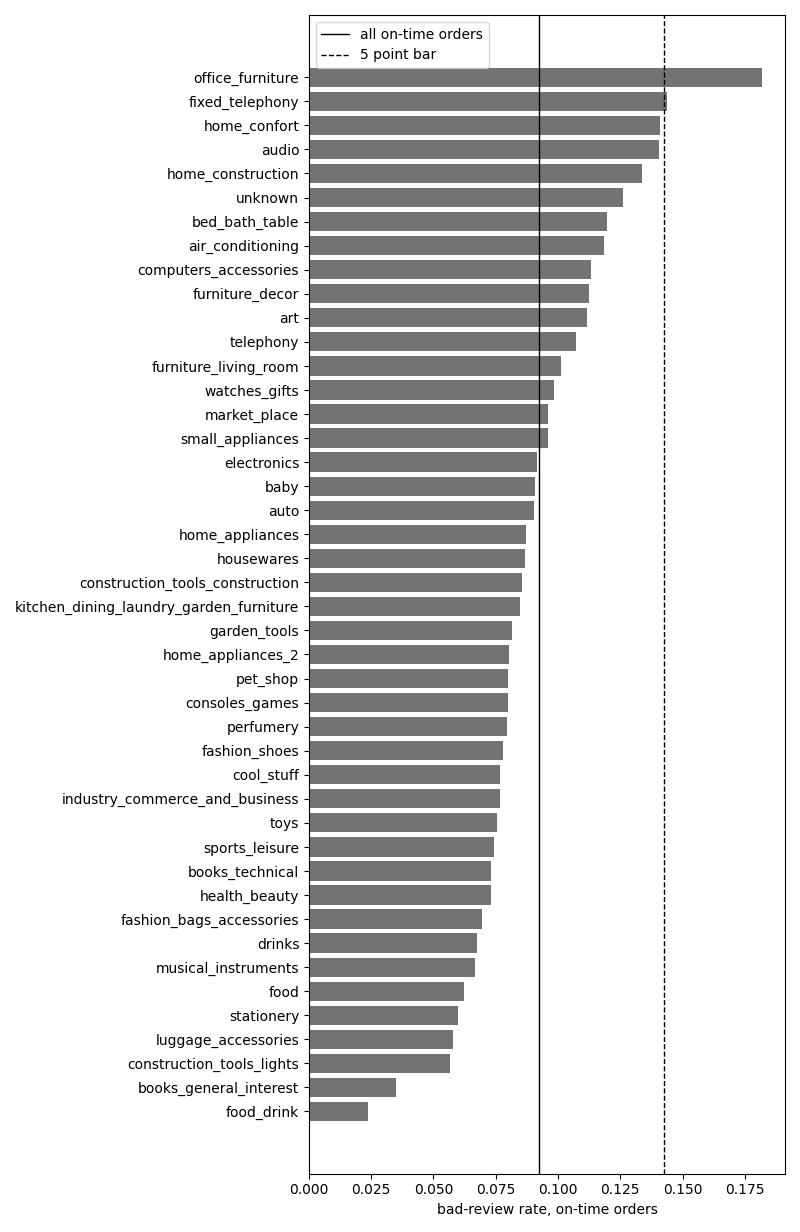

In [4]:
add_window(con)
counts = run_sql(con, "category_rates.sql")

on_time_reviewed = int(counts["on_time_reviewed"].sum())
on_time_bad = int(counts["on_time_bad"].sum())
overall_on_time = on_time_bad / on_time_reviewed

print(f"orders: {int(counts['orders'].sum())}")
print(f"bad-review rate: {counts['bad'].sum() / counts['reviewed'].sum():.4f}")
print(f"late share: {counts['late'].sum() / counts['delivered'].sum():.4f}")
print(f"on-time bad-review rate: {overall_on_time:.4f}")
print(f"categories under {MIN_CATEGORY_ORDERS} orders: {int((counts['orders'] < MIN_CATEGORY_ORDERS).sum())}")

ranked = counts.loc[counts["orders"] >= MIN_CATEGORY_ORDERS].copy()
ranked["bad_review_rate"] = ranked["bad"] / ranked["reviewed"]
ranked["late_share"] = ranked["late"] / ranked["delivered"]
ranked["on_time_rate"] = ranked["on_time_bad"] / ranked["on_time_reviewed"]
ranked["on_time_gap"] = ranked["on_time_rate"] - overall_on_time
ranked["passes"] = ranked["on_time_gap"] >= MIN_ON_TIME_GAP
ranked = ranked.sort_values("on_time_gap", ascending=False)

show = ranked[
    [
        "category",
        "orders",
        "bad_review_rate",
        "late_share",
        "on_time_reviewed",
        "on_time_rate",
        "on_time_gap",
        "passes",
    ]
]
display(show.round(4))

chart(ranked, overall_on_time)
display(Image(filename=str(CATEGORY_CHART)))

#### Conclusion: categories with bad reviews that are not explained by late delivery

Across 99,092 orders in the window, 14.6% of reviewed orders have a bad review and 6.8% of delivered orders arrive late. Among on-time orders the bad-review rate is still 9.25%, so lateness explains only part of the problem. To find categories where something else is going on, we compare each category's on-time bad-review rate with this 9.25% baseline and flag categories that exceed it by at least 5 pp. We only rank categories with at least 200 orders, which leaves 44 categories and excludes 30 smaller ones.

Two categories pass the bar:
- **office_furniture:** 18.2% bad reviews on on-time orders (+9.0 pp, 1,137 reviewed orders). This is the clearest signal. It is the only category far above the bar, and it has enough reviews for the gap to be reliable. Its late share (8.1%) is only slightly above average, so delivery does not explain it.
- **fixed_telephony:** 14.4% (+5.1 pp, 195 reviewed orders). It passes only just, and with fewer than 200 reviews the estimate is noisy.

In [5]:
from src.seller_check import main as seller_check

seller_check()

fixed_telephony
  sellers: 46
  on-time reviews: 195
  on-time bad reviews: 28
  biggest seller: 2138ccb85b11a4ec1e37afbd1c8eda1f
  biggest seller share of bad reviews: 0.1429
  biggest seller share of on-time orders: 0.1692
  one seller: False
  other sellers on-time rate: 0.1481
  other sellers gap: 0.0557
  other sellers still pass: True

office_furniture
  sellers: 28
  on-time reviews: 1137
  on-time bad reviews: 207
  biggest seller: 7c67e1448b00f6e969d365cea6b010ab
  biggest seller share of bad reviews: 0.7826
  biggest seller share of on-time orders: 0.7027
  one seller: True
  other sellers on-time rate: 0.1331
  other sellers gap: 0.0407
  other sellers still pass: False



#### Conclusion: is the category signal driven by one seller?

For the two categories that passed the 5 pp bar, we checked whether a single seller is behind the on-time bad-review rate, and whether the category still passes without that seller.

**office_furniture is mostly one seller.** 28 sellers sell in this category, but the biggest one (`7c67e144...`) accounts for 70% of the on-time reviewed orders and 78% of the on-time bad reviews, so it is flagged as a one-seller category. Its own on-time bad-review rate is about 20%, against 13.3% for the other 27 sellers. Without it, the category sits 4.1 pp above the 9.25% baseline, just under the 5 pp bar, so it no longer passes. The other sellers are still above baseline, but the gap is too small to call.

**fixed_telephony is not driven by one seller.** The biggest of its 46 sellers has 17% of on-time orders and 14% of the bad reviews, so it is not driving the result. Without it, the category is still 5.6 pp above baseline (14.8%) and passes. The sample is small, though: 195 on-time reviews and 28 bad ones, so the estimate is noisy.

The office_furniture signal is mainly a seller problem, not a category problem, so the action is to review that seller and not the whole category. fixed_telephony is the only category where the gap is spread across sellers, but I would call it a watch item because of the small sample.